In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy
from tqdm import tqdm
from modules import gendata, SI_SeqFS_DA, DA_SeqFS


Generate data

In [ ]:
np.random.seed(0)

In [2]:
ns = 20
nt = 10
truebeta= [0, 0, 0]
p = len(truebeta)
print('true beta:', truebeta)

true_beta_s = np.full((p,1), 2) #source's beta
true_beta_t = np.array(truebeta).reshape((-1,1)) #target's beta

K = 2 # select k features
# generate data
# Xs, Xt, Ys, Yt, Sigma_s, Sigma_t = gendata.generate(ns, nt, p, true_beta_s, true_beta_t)

true beta: [0, 0, 0]


### SI-SeqFS-DA with Forward Selection

In [ ]:

list_p_value = []
alpha = 0.05  
rejected = 0
detected = 0

max_iteration = 200
iter = range(max_iteration)

list_p_value = []
for i in tqdm(iter):
    # generate data
    np.random.seed(i)
    Xs, Xt, Ys, Yt, Sigma_s, Sigma_t = gendata.generate(ns, nt, p, true_beta_s, true_beta_t, fixed_seed=i)
    list_selected_features = DA_SeqFS.DA_SeqFS(Xs, Ys, Xt, Yt, Sigma_s, Sigma_t,K, method='forward')
    j = np.random.randint(0, len(list_selected_features))
    pvalue = SI_SeqFS_DA.SI_SeqFS_DA(Xs, Ys, Xt, Yt, K, Sigma_s, Sigma_t, method='forward', jth=j)
    print(f"NEW Iteration {i+1}/{max_iteration}, p-value: {pvalue}")
    
    list_p_value.append(pvalue)

for i in list_p_value:
    if i <= alpha:
        rejected += 1
    else:
        detected += 1
FPR = rejected / (rejected + detected)


100%|██████████| 200/200 [21:00<00:00,  6.30s/it]


False positive rate: 0.095
Uniform check (KS-Test result): 3.391892410451751e-08


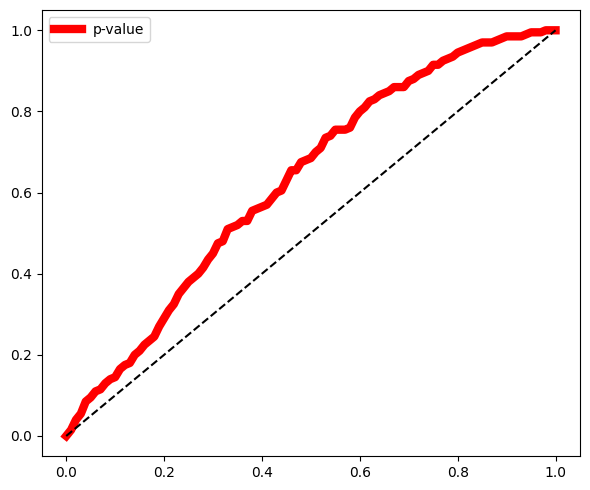

In [4]:
kstest = scipy.stats.kstest(list_p_value, 'uniform')
print(f"False positive rate: {FPR}")
print(f'Uniform check (KS-Test result): {kstest.pvalue}')

# plt.rcParams.update({'font.size': 18})
plt.figure(figsize=(6, 5))
grid = np.linspace(0, 1, 101)
plt.plot(grid, sm.distributions.ECDF(np.array(list_p_value))(grid), 'r-', linewidth=6, label='p-value')
plt.plot([0, 1], [0, 1], 'k--')
plt.legend()
plt.tight_layout()
plt.show()

### SI-SeqFS-DA with Backward Selection

In [5]:

list_p_value = []
alpha = 0.05  
rejected = 0
detected = 0

max_iteration = 200
iter = range(max_iteration)

list_p_value = []
for i in iter:
    # generate data
    Xs, Xt, Ys, Yt, Sigma_s, Sigma_t = gendata.generate(ns, nt, p, true_beta_s, true_beta_t)
    pvalue = SI_SeqFS_DA.SI_SeqFS_DA(Xs, Ys, Xt, Yt, K, Sigma_s, Sigma_t, method='backward', jth = None)
    list_p_value.append(pvalue)

for i in list_p_value:
    if i <= alpha:
        rejected += 1
    else:
        detected += 1
FPR = rejected / (rejected + detected)


KeyboardInterrupt: 

False positive rate: 0.1
Uniform check (KS-Test result): 1.4598330091670874e-08


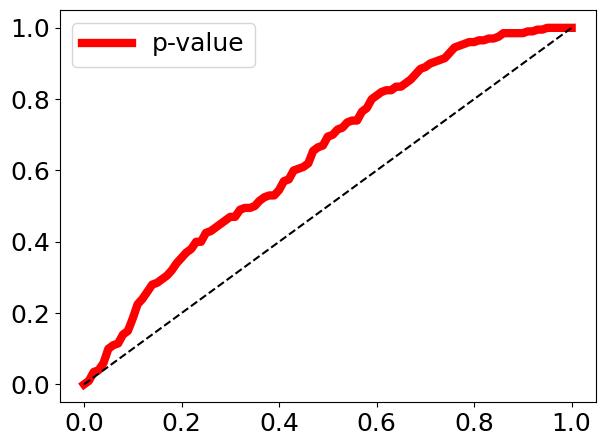

In [ ]:
kstest = scipy.stats.kstest(list_p_value, 'uniform')
print(f"False positive rate: {FPR}")
print(f'Uniform check (KS-Test result): {kstest.pvalue}')

plt.rcParams.update({'font.size': 18})
grid = np.linspace(0, 1, 101)
plt.plot(grid, sm.distributions.ECDF(np.array(list_p_value))(grid), 'r-', linewidth=6, label='p-value')
plt.plot([0, 1], [0, 1], 'k--')
plt.legend()
plt.tight_layout()
plt.show()